In [ ]:
print("Hello")

: 

In [1]:
print("Hello")

Hello


# Predicting Continental Ancestry from Genotype Data

## Objective:
Use machine learning to predict which continental group a person belongs to by using only their genetic data.

## Data
- **Source:** 1000 Genomes Project, Phase 3, chromosome 22 (N= 2,504 people with 10,55,454 variants)
- **Labels:** Five continental groups: African (AFR), Admixed American (AMR), East Asian (EAS), European (EUR) and South Asian (SAS)

## Methodology
1. Quality Control of the genetic data with PLINK2
QC Parameters: (a) SNPs with two alleles
               (b) MAF < 0.05
               (c) geno 0.05
2. Linkage disequilibrium (LD) pruning was performed using a sliding window of 50 SNPs, advancing by 5 SNPs at each step, with an \(r^2\) threshold of 0.2 to remove highly correlated SNPs.
3. Principal component analysis (PCA) was ran and first 10 components for each person was kept.
4. PCA results and each person's continental group were merged together.
2. First two principal components of each person's data was plotted in X and Y axes.
3. the data was splitted into a training set (80%) and a test set (20%).
4. Two machine-learning models, Random Forest and Logistic Regression were trained and evaluated on the test set to compare their performance in predicting ancestry.

In [2]:
import pandas as pd

pcs = pd.read_csv("../data/pca.eigenvec", sep=r"\s+")
pcs.columns = [c.lstrip("#") for c in pcs.columns]

labels = pd.read_csv("../data/integrated_call_samples_v3.20130502.ALL.panel.txt", sep="\t")

df = pcs.merge(labels, left_on="IID", right_on="sample")

print(df.shape)
df.head()

(2504, 18)


,FID,IID,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,sample,pop,super_pop,gender,Unnamed: 4,Unnamed: 5
0,0,HG00096,-0.010481,-0.028821,0.007892,0.025542,-0.006183,0.021681,0.000772,-0.017934,-0.008483,0.019908,HG00096,GBR,EUR,male,NaN,NaN
1,0,HG00097,-0.011923,-0.025420,0.007991,0.012150,-0.003498,-0.011932,-0.034095,0.011245,-0.021893,-0.040758,HG00097,GBR,EUR,female,NaN,NaN
2,0,HG00099,-0.010192,-0.025073,0.002252,0.011974,-0.005847,-0.007110,0.002727,-0.007757,-0.006874,0.015383,HG00099,GBR,EUR,female,NaN,NaN
3,0,HG00100,-0.009474,-0.028263,0.009318,0.025198,-0.018493,0.031161,-0.005330,0.019728,-0.009594,0.009610,HG00100,GBR,EUR,female,NaN,NaN
4,0,HG00101,-0.010032,-0.024628,0.007245,0.014214,-0.002290,0.019927,0.005312,0.001674,-0.010430,0.028225,HG00101,GBR,EUR,male,NaN,NaN


## Visualising the PCA Results
Each dot is one person. The position comes from the first two principal components (PC1 and PC2), which summarise the largest differences in genotypes between people. The colour shows the continental group from the 1000 Genomes panel. If individuals cluster according to their genetic similarities, their genotype data may contain informative patterns of population ancestry that machine-learning models can learn to identify and use for ancestry prediction.

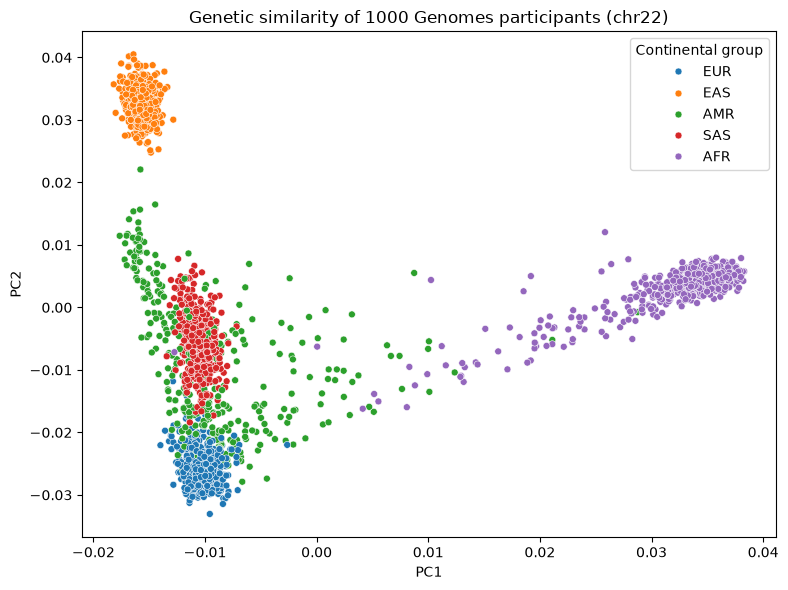

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="PC1", y="PC2", hue="super_pop", s=25)
plt.title("Genetic similarity of 1000 Genomes participants (chr22)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Continental group")
plt.tight_layout()
plt.savefig("../results/pca_plot.png", dpi=200)
plt.show()

**Observation:** People from the same continental group mostly cluster together, so the first two principal components already carry information about ancestry. East Asian (EAS) samples (orange colour) form a tight cluster at the top left and European (EUR) samples (blue colour) form a tight cluster at the bottom. African (AFR) samples (purple colour) sit far to the right, with a tail of individuals extending towards the centre of the plot.

South Asian (SAS) samples (red colour) lie between the European and East Asian clusters and overlap partly with EUR and AMR. The Admixed American (AMR) group (green colour) is the most spread out with individuals scattered between the European, African and East Asian clusters. This fits the idea that Admixed American individuals have ancestry from several source populations. Although the PCA plot suggests potential admixture within the Admixed American population but alone it cannot quantify admixture proportions or confirm the underlying ancestral contributions. Further validation using appropriate admixture analysis methods is required.

**Expected model performance:** Based on the observed clustering patterns, the classification models are expected to distinguish East Asian, European and African individuals relatively well because these groups exhibit comparatively distinct distributions in the PCA plot. In contrast, classification errors may be more frequent for South Asian and Admixed American individuals because of the partial overlap between these groups and other populations. However, actual predictive performance must be established using the test-set results rather than inferred from the PCA plot alone.

## Splitting of the Data
The first 10 principal components (PCs) for each individual were used as input features, while the corresponding continental super-population group was used as the target label. The dataset was divided into training (80%) and test (20%) sets using stratified sampling to preserve the relative representation of each super-population group in both subsets. The training set comprised 2,003 individuals, while the independent test set included 501 individuals which was reserved for evaluating model performance on unseen data. The test set consisted of 132 African (AFR), 101 East Asian (EAS), 101 European (EUR), 98 South Asian (SAS), and 69 Admixed American (AMR) individuals. This stratified split enabled a more representative assessment of the models’ ability to classify individuals across the five continental super-population groups.

In [5]:
from sklearn.model_selection import train_test_split

features = [f"PC{i}" for i in range(1, 11)]
X = df[features]
y = df["super_pop"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set:", X_train.shape[0], "people")
print("Test set:", X_test.shape[0], "people")
print()
print("Test set by continental group:")
print(y_test.value_counts())

Training set: 2003 people
Test set: 501 people

Test set by continental group:
super_pop
AFR    132
EAS    101
EUR    101
SAS     98
AMR     69
Name: count, dtype: int64


## Training and testing of two models
Random Forest and Logistic Regression models were trained on the training set only and then scored on the held-out test set. For each continental group precision, recall and F1 and overall accuracy were estimated.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print("=" * 50)
    print(name)
    print("=" * 50)
    print(classification_report(y_test, predictions[name]))

Random Forest
              precision    recall  f1-score   support

         AFR       0.98      0.98      0.98       132
         AMR       0.95      0.90      0.93        69
         EAS       1.00      1.00      1.00       101
         EUR       0.96      0.99      0.98       101
         SAS       1.00      1.00      1.00        98

    accuracy                           0.98       501
   macro avg       0.98      0.97      0.98       501
weighted avg       0.98      0.98      0.98       501

Logistic Regression
              precision    recall  f1-score   support

         AFR       0.84      1.00      0.91       132
         AMR       1.00      0.32      0.48        69
         EAS       0.99      1.00      1.00       101
         EUR       0.83      1.00      0.91       101
         SAS       1.00      1.00      1.00        98

    accuracy                           0.91       501
   macro avg       0.93      0.86      0.86       501
weighted avg       0.92      0.91      0.89

## Where do the models make mistakes?
The confusion matrices shown below, for each true group (rows), how the model labelled those people (columns). Numbers on the diagonal are correct predictions.

### Confusion Matrix Analysis
The confusion matrices were examined to compare the classification performance of the Random Forest and Logistic Regression models across the five continental super-population groups: AFR, AMR, EAS, EUR and SAS. The Random Forest model achieved an overall accuracy of 98% indicating strong agreement between the predicted and actual population labels. Logistic Regression achieved an accuracy of 91% suggesting comparatively lower classification performance. The confusion matrices provide further insight into group-specific predictions by showing the number of correctly classified individuals along the diagonal and misclassified individuals in the off-diagonal cells. In particular, the performance of both models for the Admixed American (AMR) group requires attention as Logistic Regression achieved a recall of 0.32 for this group indicating that it correctly identified approximately 32% of the actual AMR individuals in the test set. The distribution of the remaining AMR predictions should be examined to identify the population groups with which AMR individuals were most frequently confused.

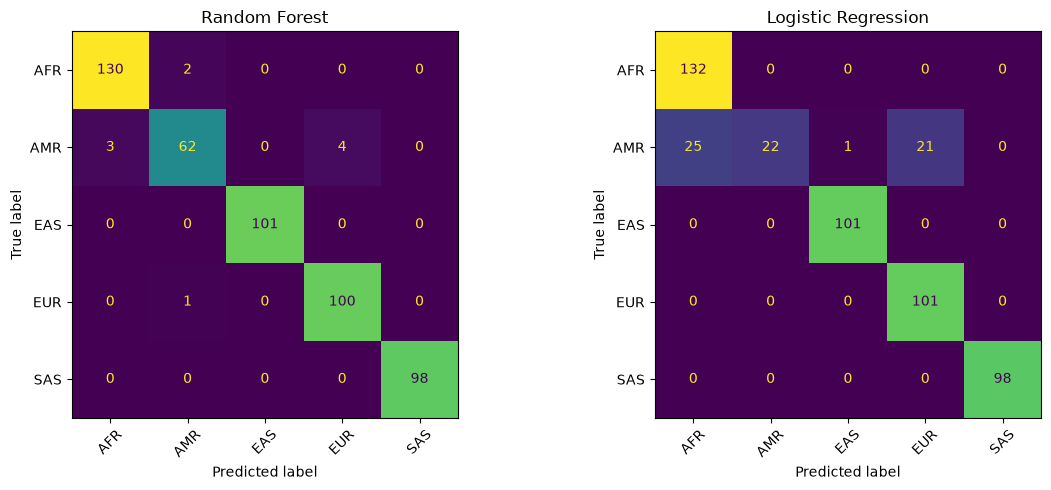

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, ax=ax, xticks_rotation=45, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../results/confusion_matrices.png", dpi=200)
plt.show()

### Inference

The confusion matrices demonstrate differences in classification performance between Random Forest and Logistic Regression across the five continental super-population groups: African (AFR), Admixed American (AMR), East Asian (EAS), European (EUR) and South Asian (SAS).

The Random Forest model correctly classified 491 of the 501 individuals in the test set, achieving an overall accuracy of approximately 98.00%. It performed particularly well for the AFR, EAS, EUR and SAS groups. Among the 69 AMR individuals, 62 were correctly classified, while three were misclassified as AFR and four as EUR. Thus, Random Forest achieved an AMR recall of approximately 89.86%.

Logistic Regression correctly classified 454 of the 501 test individuals corresponding to an accuracy of approximately 90.62%. It correctly classified all individuals belonging to the AFR, EAS, EUR and SAS groups in this test set. However, its performance for AMR was considerably lower: only 22 of the 69 AMR individuals were correctly identified giving a recall of approximately      31.88%. Of the remaining AMR individuals, 25 were misclassified as AFR, 21 as EUR and one as EAS.

These results indicate that AMR (Admixed American) was the most challenging group for Logistic Regression, whereas Random Forest substantially reduced misclassification of this group. The difference suggests that Random Forest captured patterns in the principal component features that were more effective for distinguishing AMR individuals from the other groups. Nevertheless, the confusion matrices describe performance on this particular test set and do not, by themselves, establish how well either model will generalize to other populations or datasets.

### Conclusion

This project investigated the application of machine-learning methods for predicting continental ancestry from human genotype data using the 1000 Genomes Project dataset. Genotype data were subjected to quality control and linkage disequilibrium pruning, followed by principal component analysis (PCA) to derive features representing major patterns of genetic variation. The first 10 principal components were used as predictors and the five continental super-population groups were used as target labels. Random Forest and Logistic Regression were trained using an 80:20 stratified train–test split and evaluated on an independent test subset.

Both models demonstrated promising classification performance, but Random Forest outperformed Logistic Regression achieving approximately 98.00% test accuracy compared with 90.62% for Logistic Regression. The most notable difference was observed for the Admixed American group, for which Random Forest achieved approximately 89.86% recall, compared with 31.88% for Logistic Regression. This finding highlights the importance of evaluating class-specific performance alongside overall accuracy, particularly when genetic populations exhibit overlapping patterns of variation.

Overall, the findings demonstrate that PCA-derived features can support machine-learning-based prediction of continental population labels from genotype data, with Random Forest providing the stronger performance in this analysis. However, the results should be interpreted within the limitations of the study, including the use of chromosome 22 alone, a single train–test split and the possibility of information leakage because PCA was performed before the data were split. Related individuals may also occur in both subsets. Future work should evaluate additional chromosomes or genome-wide data, perform PCA within an appropriate training and evaluation framework and use repeated or independent validation to assess the robustness and generalizability of the models.